# 02 · Customers: who pays OP Mainnet

- **Customer** = the app behind the destination address of a transaction (file 06). The sender pays the fee, but the destination is the product that created the demand. Addresses are mapped to apps in `sql/customers.sql` (mart `m_customer_app`) with file 07 labels plus the curated `data/overrides/address_overrides.csv`.
- **Last 12 months (TTM)** = 2025-09-16 to 2026-09-15. Shares are of all TTM sequencer fees in file 06, the long tail included.
- **Long tail** = file 06's `'other'` row: addresses below 10k transactions and 0.25 ETH of fees in every month, plus contract creations. It is kept as the `long_tail` segment but left out of rankings (thousands of small apps, not one customer).
- **Wintermute** = its two labelled contracts plus an unlabelled successor contract attributed **by inference**, so it is shown as "Wintermute (inferred)".

Writes every `cust_` number to `output/numbers.json`.

In [1]:
import sys
from collections import Counter
from pathlib import Path

import duckdb
import pandas as pd
import plotly.graph_objects as go

sys.path.insert(0, str(Path.cwd().parent))  # project root, when run from notebooks/
from src import numbers
from src.build_db import ROOT
from src.charts import figure, show
from src.format import usd

numbers.clear("cust_")
con = duckdb.connect(str(ROOT / "data" / "opm.duckdb"), read_only=True)

PRETTY = {"etherfi": "ether.fi", "tether": "Tether (USDT)", "circle": "Circle (USDC)", "optimism": "OP token",
          "erc4337": "ERC-4337 EntryPoints", "uniswap": "Uniswap", "chainlink": "Chainlink", "worldcoin": "Worldcoin",
          "velodrome": "Velodrome", "safe": "Safe wallets", "overtime": "Overtime", "farcaster": "Farcaster",
          "aave": "Aave", "tria": "Tria", "veda": "Veda", "hyperlane": "Hyperlane", "human": "Human (Holonym)",
          "1inch": "1inch", "walletconnect": "WalletConnect (WCT)", "wintermute": "Wintermute (inferred)"}
APP_NOTES = {"unlabeled-6777c0": "prediction mkt"}  # curated notes for unnamed apps, keyed by app
# unnamed apps are keyed by full address (curated ones by 6 hex); show 6 hex unless two apps share that prefix
UNNAMED_HEX = con.sql("select distinct app from m_customer_app where app like 'unlabeled-%'").df()["app"].str.removeprefix("unlabeled-")
PREFIX_COUNT = Counter(h[:6] for h in UNNAMED_HEX)


def pretty(app: str, segment: str = "") -> str:
    if app.startswith("unlabeled-"):
        h = app.removeprefix("unlabeled-")
        note = APP_NOTES.get(app, "bot" if segment == "bots_automation" else "unlabeled")
        return f"0x{h[:6] if PREFIX_COUNT[h[:6]] == 1 else h[:10]}… ({note})"
    return PRETTY.get(app, app.replace("-", " ").title())

## How much of TTM fees can we put a name on, before and after the curated overrides?

Overrides come first. Every top-40 TTM address with no `entity_project`, `dune_namespace` or `dune_owner` was checked on behaviour and on the block explorer (Blockscout, `explorer.optimism.io`); a named app needs explicit evidence such as a verified contract name, otherwise it stays `unlabeled-<hex>` with a segment from behaviour. Then labels, in priority order: `entity_project` > `dune_namespace` > `dune_owner` > Allium `display_name` brand. Dune's `dune_owner = 'sushiswap'` is ignored (it is applied to Multicall3, Safe wallets, MEV bots and more).

In [2]:
coverage = con.sql("""
    with f as (
        select to_address as address, sum(total_fee_usd) as fee_usd
        from contract_activity
        where date between '2025-09-16' and '2026-09-15'
        group by address
    )
    select sum(f.fee_usd) filter (where a.app not like 'unlabeled-%' and a.app <> 'other') / sum(f.fee_usd) as named_after_overrides,
           sum(f.fee_usd) filter (where a.label_app not like 'unlabeled-%' and a.label_app <> 'other') / sum(f.fee_usd) as named_labels_only,
           (select count(*) from address_overrides) as overrides,
           (select count(*) from address_overrides where app not like 'unlabeled-%') as overrides_named
    from m_customer_app a
    join f using (address)
""").df()
c = coverage.iloc[0]
numbers.record("cust_named_coverage", c["named_after_overrides"], "share of TTM sequencer fees mapped to a named app (after overrides); denominator includes long tail")
numbers.record("cust_named_coverage_before", c["named_labels_only"], "same, labels only (before overrides)")
numbers.record("cust_overrides_n", c["overrides"], "addresses in data/overrides/address_overrides.csv")
numbers.record("cust_overrides_named", c["overrides_named"], "overrides assigned a named app with explicit explorer evidence; rest are behaviour-only unlabeled-<hex>")
coverage

,named_after_overrides,named_labels_only,overrides,overrides_named
0,0.373805,0.17466,32,3


## Which curated overrides carry the most fees?

In [3]:
con.sql("""
    with f as (
        select to_address as address, sum(total_fee_usd) as fee_usd
        from contract_activity
        where date between '2025-09-16' and '2026-09-15'
        group by address
    )
    select o.app, o.segment, count(*) as addresses, sum(f.fee_usd) as ttm_fee_usd,
           sum(f.fee_usd) / (select sum(fee_usd) from f) as share
    from address_overrides o
    left join f using (address)
    group by o.app, o.segment
    order by ttm_fee_usd desc
""").df()

,app,segment,addresses,ttm_fee_usd,share
0,wintermute,bots_automation,1,179753.739025,0.143118
1,etherfi,stablecoin_payments,1,70368.159436,0.056027
2,unlabeled-7518ba,bots_automation,2,57733.155495,0.045967
3,unlabeled-8e0ff4,bots_automation,1,40348.117196,0.032125
4,unlabeled-1dc680,bots_automation,2,35150.222926,0.027986
5,unlabeled-802b65,bots_automation,1,34182.955353,0.027216
6,unlabeled-731032,bots_automation,1,29754.462323,0.023690
7,unlabeled-6777c0,other_labeled,1,29315.323392,0.023341
8,unlabeled-d6e5bb,bots_automation,2,26553.833525,0.021142
9,unlabeled-983744,bots_automation,1,22146.537660,0.017633


## Who were our biggest customers in the last 12 months?

In [4]:
# senders = average daily distinct senders over the app's active days, summed over its addresses (daily uniques are the finest grain)
ranking = con.sql("""
    with t as (
        select a.app, a.segment,
               sum(c.total_fee_usd) as fee_usd,
               sum(c.txs) as txs,
               sum(c.distinct_senders) / count(distinct c.date) as senders
        from contract_activity c
        join m_customer_app a on a.address = c.to_address
        where c.date between '2025-09-16' and '2026-09-15'
        group by a.app, a.segment
    )
    select row_number() over (order by fee_usd desc, app) as rank,
           app, segment, fee_usd,
           fee_usd / (select sum(fee_usd) from t) as share,  -- of all TTM fees, long tail included
           sum(fee_usd) over (order by fee_usd desc, app rows unbounded preceding) / (select sum(fee_usd) from t) as cum_share,
           txs, senders,
           fee_usd / txs as fee_per_tx_usd
    from t
    where app <> 'other' and fee_usd > 0
    order by rank
""").df()
top1 = ranking.iloc[0]
numbers.record("cust_n_apps_ttm", len(ranking), "apps with TTM sequencer fees > 0, excluding the 'other' long tail")
numbers.record("cust_top1_share", top1["share"], f"largest TTM fee payer ({top1['app']}; 'wintermute' is inferred, see overrides): its share of all TTM sequencer fees")
numbers.record("cust_wintermute_ttm_share", ranking.loc[ranking["app"] == "wintermute", "share"].item(), "Wintermute (inferred) share of all TTM sequencer fees")
ranking.head(15)

,rank,app,segment,fee_usd,share,cum_share,txs,senders,fee_per_tx_usd
0,1,wintermute,bots_automation,179753.739025,0.143118,0.143118,6186104.0,15.531507,0.029058
1,2,etherfi,stablecoin_payments,80393.218448,0.064008,0.207127,7971804.0,33.625000,0.010085
2,3,unlabeled-7518ba,bots_automation,57733.155495,0.045967,0.253093,3515.0,5.253165,16.424795
3,4,unlabeled-8e0ff4,bots_automation,40348.117196,0.032125,0.285218,115.0,1.190476,350.853193
4,5,tether,stablecoin_payments,36071.117113,0.028720,0.313938,3428455.0,4133.027397,0.010521
5,6,unlabeled-1dc680,bots_automation,35150.222926,0.027986,0.341924,603.0,7.744186,58.292244
6,7,unlabeled-802b65,bots_automation,34182.955353,0.027216,0.369140,2763641.0,32.439655,0.012369
7,8,unlabeled-731032,bots_automation,29754.462323,0.023690,0.392830,13507.0,1.096419,2.202892
8,9,unlabeled-6777c0,other_labeled,29315.323392,0.023341,0.416171,331645.0,9.703180,0.088394
9,10,uniswap,dex,26672.400239,0.021236,0.437407,1832270.0,477.501370,0.014557


## How much do the top 10 pay, and how many apps make up 80% of fees?

In [5]:
concentration = con.sql("""
    select sum(share) filter (where rank <= 10) as top10_share,
           min(rank) filter (where cum_share >= 0.8) as apps_paying_80pct,
           count(*) as apps_paying_fees
    from ranking
""").df()
numbers.record("cust_top10_share", concentration["top10_share"][0], "top 10 apps' share of all TTM sequencer fees (denominator incl. long tail)")
numbers.record("cust_n_apps_80pct", concentration["apps_paying_80pct"][0], "number of top apps that together pay 80% of all TTM sequencer fees")
concentration

,top10_share,apps_paying_80pct,apps_paying_fees
0,0.437407,84,696


## What does the top 15 look like on a chart?

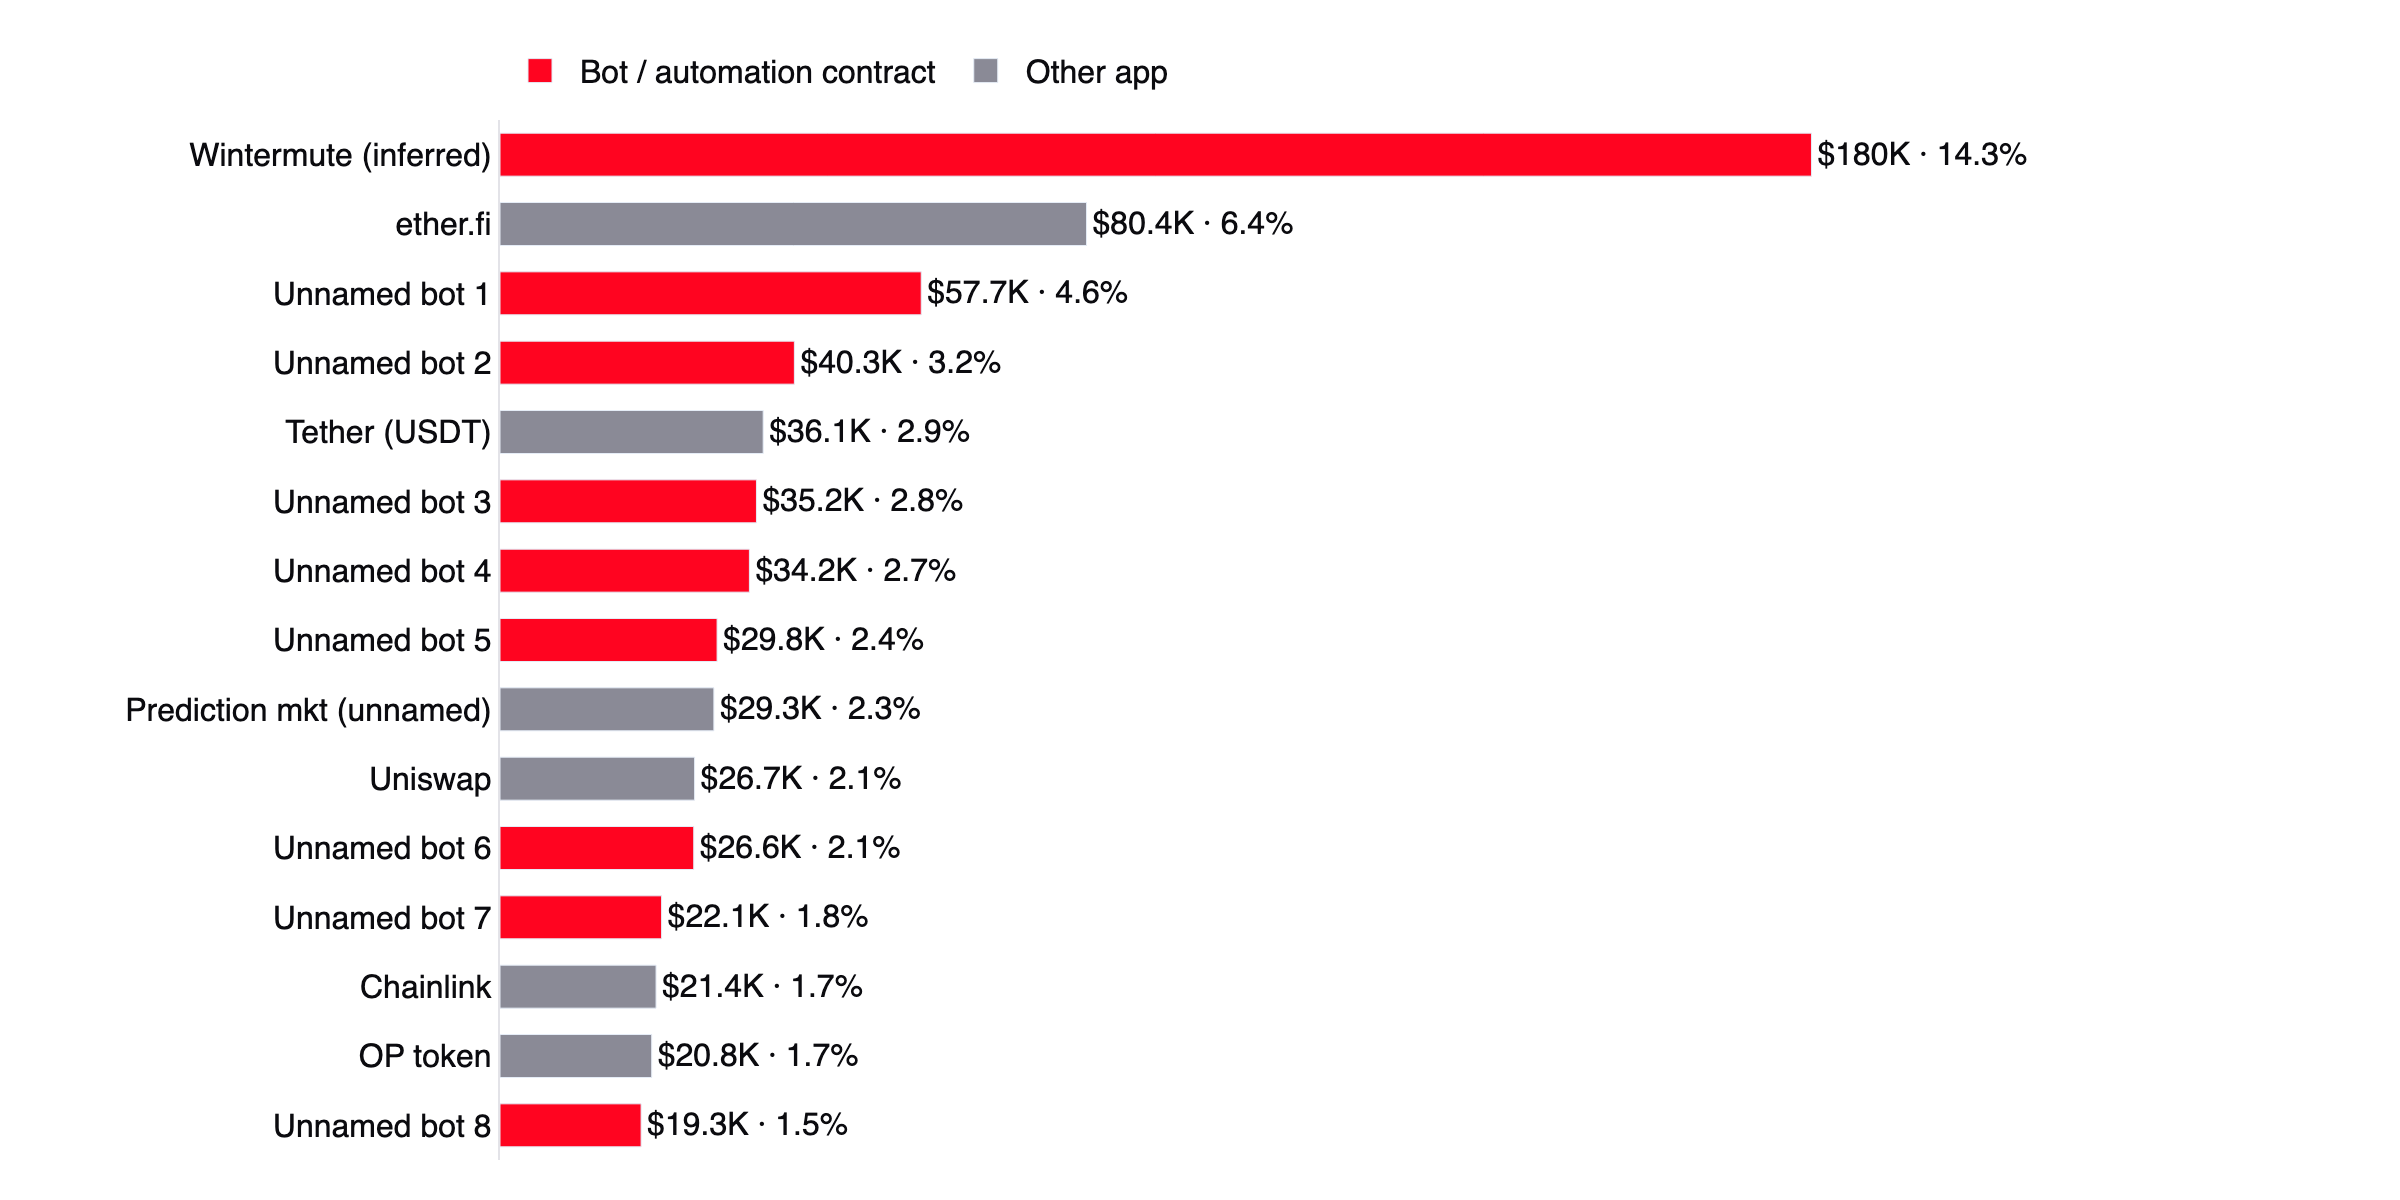

In [6]:
top15 = ranking.head(15).iloc[::-1]  # largest at the top


def chart_names(apps: list[str], segments: list[str]) -> list[str]:
    """Unnamed addresses become 'Unnamed bot 1..n' in rank order; the addresses are in the table above."""
    seen: dict[str, int] = {}
    names = []
    for app, seg in zip(apps, segments):
        if app.startswith("unlabeled-") and app not in APP_NOTES:
            kind = "Unnamed bot" if seg == "bots_automation" else "Unnamed contract"
            seen[kind] = seen.get(kind, 0) + 1
            names.append(f"{kind} {seen[kind]}")
        else:
            names.append(pretty(app, seg) if app not in APP_NOTES else f"{APP_NOTES[app].capitalize()} (unnamed)")
    return names


def cust_top_apps(theme: dict) -> go.Figure:
    fig = figure(theme)
    fig.add_bar(
        x=top15["fee_usd"].tolist(), y=chart_names(top15["app"].tolist()[::-1], top15["segment"].tolist()[::-1])[::-1], orientation="h",
        marker=dict(color=[theme["op"] if s == "bots_automation" else theme["series"][2] for s in top15["segment"]]),
        width=0.62, showlegend=False,
        text=[f"{usd(v)} · {s:.1%}" for v, s in zip(top15["fee_usd"], top15["share"])], textposition="outside",
        textfont=dict(size=16, color=theme["ink"]), cliponaxis=False,
    )
    for name, color in (("Bot / automation contract", theme["op"]), ("Other app", theme["series"][2])):
        fig.add_bar(x=[None], y=[None], name=name, marker_color=color, orientation="h")
    fig.update_layout(margin=dict(l=250, r=150, t=60, b=20), bargap=0.3, legend=dict(y=1.08, font_size=16),
                      xaxis=dict(visible=False, range=[0, top15["fee_usd"].max() * 1.22]),
                      yaxis=dict(showgrid=False, tickfont=dict(size=16, color=theme["ink"])))
    return fig


show(cust_top_apps)

## What share of fees does each segment pay?

In [7]:
segments = con.sql("""
    select a.segment,
           count(distinct a.app) as apps,
           sum(c.total_fee_usd) as fee_usd,
           sum(c.total_fee_usd) / sum(sum(c.total_fee_usd)) over () as share
    from contract_activity c
    join m_customer_app a on a.address = c.to_address
    where c.date between '2025-09-16' and '2026-09-15'
    group by a.segment
    order by fee_usd desc
""").df()
share = segments.set_index("segment")["share"]
numbers.record("cust_bots_share", share["bots_automation"], "segment bots_automation share of TTM sequencer fees")
numbers.record("cust_other_share", share["long_tail"], "long tail ('other' row in file 06) share of TTM sequencer fees")
numbers.record("cust_stablecoin_share", share["stablecoin_payments"], "segment stablecoin_payments share of TTM fees (Tether, Circle, ether.fi Cash)")
segments

,segment,apps,fee_usd,share
0,bots_automation,134,657074.434775,0.523157
1,unlabeled,482,141088.083827,0.112333
2,long_tail,1,135296.461859,0.107722
3,stablecoin_payments,7,128470.072093,0.102287
4,dex,21,59728.852925,0.047556
5,other_labeled,17,53246.194747,0.042394
6,oracle_infra,10,52797.993204,0.042037
7,bridge_messaging,23,13597.484699,0.010826
8,nft_social,13,13353.679932,0.010632
9,lending,4,968.944036,0.000771


## Check: do the segments add up to file 01's fees for the year?

In [8]:
check = con.sql("""
    select (select sum(fee_usd) from segments) as segments_usd,
           sum(total_fee_usd) as file01_usd,
           (select sum(fee_usd) from segments) / sum(total_fee_usd) - 1 as gap
    from fees_daily
    where date between '2025-09-16' and '2026-09-15'
""").df()
assert abs(check["gap"][0]) < 0.001
check

,segments_usd,file01_usd,gap
0,1.255979e+06,1.255994e+06,-0.000012


## How did the segment mix move month by month?

In [9]:
mix = con.sql("""
    select month,
           case segment when 'bots_automation' then 'Bots & automation'
                        when 'stablecoin_payments' then 'Stablecoins & payments'
                        when 'unlabeled' then 'Unlabeled contracts'
                        when 'long_tail' then 'Long tail (unattributed)'
                        else 'Other identified apps' end as segment_group,
           sum(fee_usd) / sum(sum(fee_usd)) over (partition by month) as share
    from m_customer_month
    group by month, segment_group
    order by month, segment_group
""").df()
long_tail = mix[mix["segment_group"] == "Long tail (unattributed)"]
stable = mix[mix["segment_group"] == "Stablecoins & payments"]
numbers.record("cust_other_share_sep_nov_2025", long_tail.loc[long_tail["month"].between("2025-09-01", "2025-11-01"), "share"].mean(),
               "long-tail share of monthly fees, mean of Sep-Nov 2025")
numbers.record("cust_other_share_jun_aug_2026", long_tail.loc[long_tail["month"].between("2026-06-01", "2026-08-01"), "share"].mean(),
               "long-tail share of monthly fees, mean of Jun-Aug 2026")
numbers.record("cust_stablecoin_share_aug_2026", stable.loc[stable["month"] == "2026-08-01", "share"].item(),
               "stablecoins & payments share of August 2026 fees (last full month)")
mix.pivot(index="month", columns="segment_group", values="share")

segment_group,Bots & automation,Long tail (unattributed),Other identified apps,Stablecoins & payments,Unlabeled contracts
month,,,,,
2025-01-01,0.467354,0.124974,0.218361,0.068474,0.120837
2025-02-01,0.582968,0.086597,0.119228,0.053675,0.157533
2025-03-01,0.716721,0.067583,0.104771,0.025637,0.085287
2025-04-01,0.531042,0.084558,0.169345,0.020316,0.194738
2025-05-01,0.657881,0.081681,0.135645,0.030113,0.094681
2025-06-01,0.674439,0.106619,0.110937,0.036725,0.071281
2025-07-01,0.600794,0.112051,0.177650,0.031360,0.078146
2025-08-01,0.695493,0.065461,0.105221,0.037770,0.096054
2025-09-01,0.581877,0.061893,0.217994,0.044562,0.093674


## What does the monthly mix look like on a chart? (September 2026 is 1–15 Sep only)

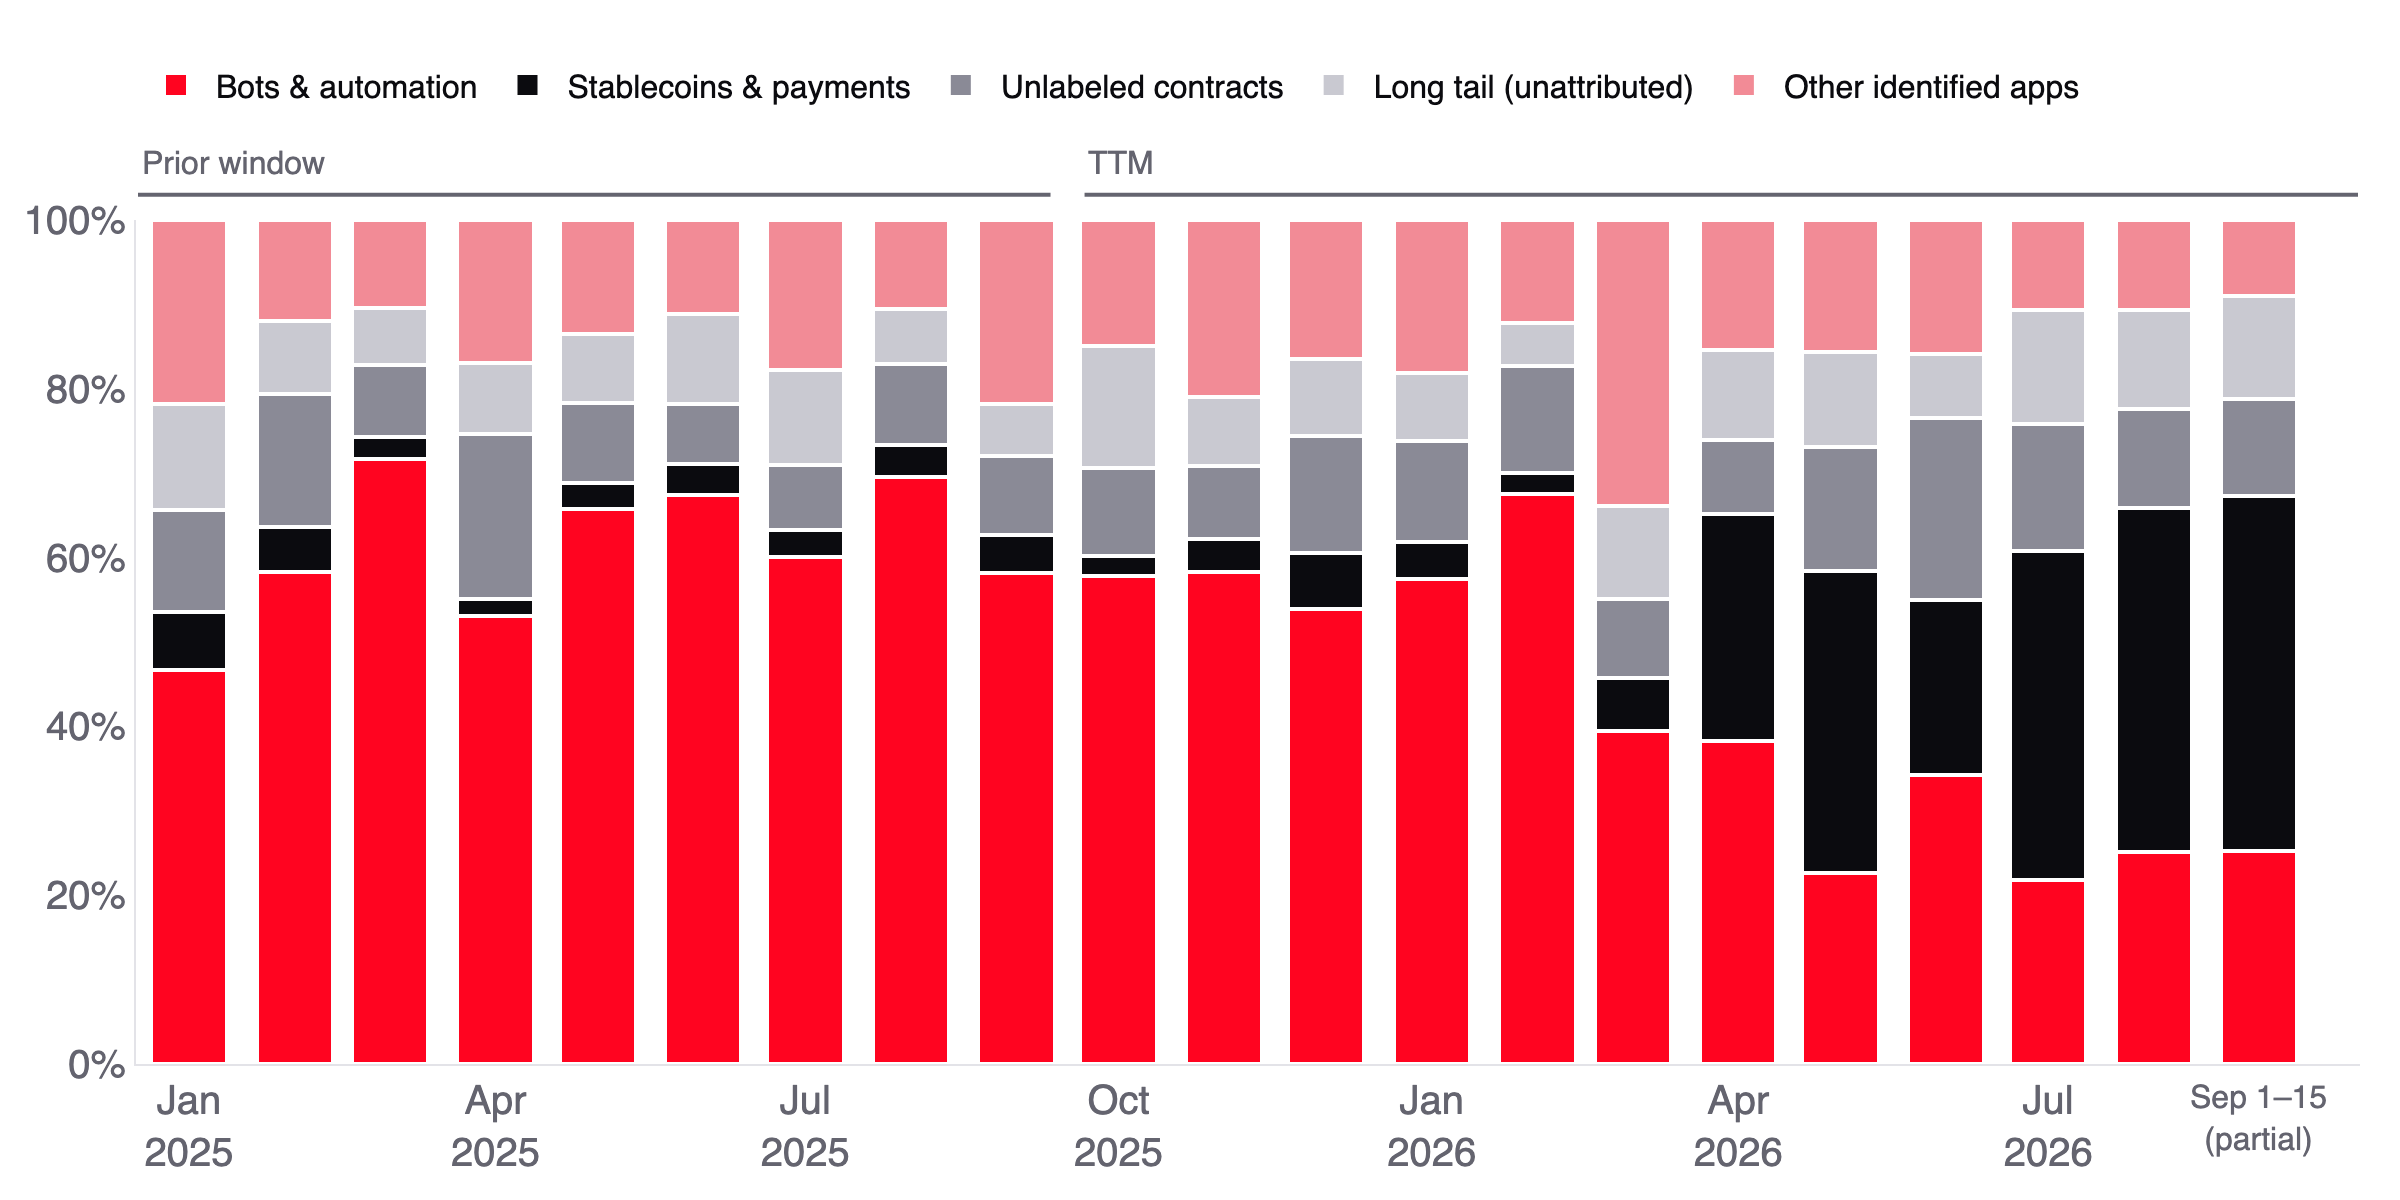

In [10]:
ORDER = ["Bots & automation", "Stablecoins & payments", "Unlabeled contracts", "Long tail (unattributed)", "Other identified apps"]
# window brackets above the bars: prior 2025-01-01..2025-09-15 and TTM 2025-09-16..2026-09-15,
# padded half a bar (15 days) at the ends, 5-day gap at the TTM boundary
PRIOR_X0, PRIOR_X1, TTM_X0, TTM_X1 = "2024-12-17", "2025-09-11", "2025-09-21", "2026-09-30"


def cust_segments(theme: dict) -> go.Figure:
    fig = figure(theme)
    # stack order keeps adjacent colours distinguishable for colour-blind readers
    colors = [theme["op"], theme["series"][1], theme["series"][2], theme["series"][3], theme["series"][4]]
    for group, color in zip(ORDER, colors):
        d = mix[mix["segment_group"] == group]
        fig.add_bar(x=d["month"].tolist(), y=(d["share"] * 100).tolist(), name=group,
                    marker=dict(color=color, line=dict(color=theme["bg"], width=2)))
    fig.add_annotation(x=mix["month"].max(), xref="x", y=0, yref="paper", yanchor="top", yshift=-6, showarrow=False,
                       text="Sep 1–15<br>(partial)", font=dict(size=16, color=theme["muted"]))
    for x0, x1, label in ((PRIOR_X0, PRIOR_X1, "Prior window"), (TTM_X0, TTM_X1, "TTM")):
        fig.add_shape(type="line", xref="x", yref="paper", x0=x0, x1=x1, y0=1.03, y1=1.03, line=dict(color=theme["muted"], width=2))
        fig.add_annotation(xref="x", yref="paper", x=x0, y=1.04, xanchor="left", yanchor="bottom", showarrow=False, text=label,
                           font=dict(size=16, color=theme["muted"]))
    fig.update_layout(barmode="stack", bargap=0.2, margin=dict(l=60, r=20, t=110, b=40),
                      legend=dict(y=1.2, font_size=16, traceorder="normal"),
                      yaxis=dict(range=[0, 100], ticksuffix="%", showgrid=False), xaxis=dict(tickformat="%b<br>%Y", dtick="M3"))
    return fig


show(cust_segments)

## Do bots pay the bills? Fees to addresses with at most 10 daily senders

Daily distinct senders is the finest sender grain in the source. An address is *low-sender* if its median daily distinct senders over its active TTM days is ≤ 10.

In [11]:
low = con.sql("""
    with a as (
        select to_address, median(distinct_senders) as median_senders, sum(total_fee_usd) as fee_usd, sum(txs) as txs
        from contract_activity
        where date between '2025-09-16' and '2026-09-15' and to_address <> 'other'
        group by to_address
    )
    select median_senders <= 10 as low_sender,
           count(*) as addresses,
           sum(fee_usd) as fee_usd,
           sum(fee_usd) / (select sum(total_fee_usd) from contract_activity where date between '2025-09-16' and '2026-09-15') as share,
           sum(txs) as txs,
           sum(fee_usd) / sum(txs) as fee_per_tx_usd
    from a
    group by low_sender
    order by low_sender desc
""").df()
numbers.record("cust_low_sender_share", low.loc[low["low_sender"], "share"].item(), "share of TTM fees paid to addresses whose median daily distinct senders <= 10")
low

,low_sender,addresses,fee_usd,share,txs,fee_per_tx_usd
0,True,587,678444.252661,0.540171,244652500.0,0.002773
1,False,256,442238.706335,0.352107,373223954.0,0.001185


## Where is demand moving between the first and second half of the year?

Halves: 16 Sep 2025 – 15 Mar 2026 and 16 Mar – 15 Sep 2026, totals per half. Stablecoin transfers use Allium's `adjusted_volume_usd` (bot and wash transfers removed). Net bridged leaves out bridge aggregators to avoid double counting. Deposits are DefiLlama's headline TVL on the last day of each half.

In [12]:
activity = con.sql("""
    with flows as (
        select 1 as row_no, 'Stablecoin transfers (excl. bots)' as metric, date, adjusted_volume_usd as usd from stablecoins
        union all
        select 2, 'Money bridged in, net', date, case direction when 'inbound' then usd_volume else -usd_volume end
        from bridge_flows where bridge_type <> 'bridge_aggregator'
        union all
        select 4, 'DEX trading volume', date, total_volume_usd from dex_volume
        union all
        select 5, 'New loans', date, loan_volume_usd from lending
    ), halves as (
        select row_no, metric,
               sum(usd) filter (where date between '2025-09-16' and '2026-03-15') as h1,
               sum(usd) filter (where date between '2026-03-16' and '2026-09-15') as h2
        from flows
        group by all
        union all
        select 3, 'Deposits in apps (end of half)',
               sum(tvl_usd) filter (where date = '2026-03-15'),
               sum(tvl_usd) filter (where date = '2026-09-15')
        from tvl
        where not exclude_from_global_tvl and not has_double_counted_tvl
    )
    select metric, h1, h2, h2 / h1 - 1 as change, h2 / h1 as multiple
    from halves
    order by row_no
""").df()
tvl_start = con.sql("""
    select sum(tvl_usd) from tvl where not exclude_from_global_tvl and not has_double_counted_tvl and date = '2025-09-15'
""").fetchone()[0]
numbers.record("cust_activity_table", [dict(metric=r["metric"], h1=round(r["h1"]), h2=round(r["h2"]), change=round(r["change"], 4),
                                            multiple=round(r["multiple"], 3)) for r in activity.to_dict("records")],
               "TTM halves 2025-09-16..2026-03-15 vs 2026-03-16..2026-09-15, totals; deposits = headline TVL on the last day of each half")
numbers.record("cust_tvl_ttm_start_usd", tvl_start, "headline TVL on 2025-09-15, the day before the TTM starts")
activity

,metric,h1,h2,change,multiple
0,Stablecoin transfers (excl. bots),1.864624e+09,3.143673e+09,0.685955,1.685955
1,"Money bridged in, net",6.182822e+07,6.542804e+08,9.582230,10.582230
2,Deposits in apps (end of half),1.961986e+08,4.388878e+08,1.236956,2.236956
3,DEX trading volume,5.953092e+09,3.042112e+09,-0.488986,0.511014
4,New loans,1.287750e+09,3.637904e+08,-0.717499,0.282501


## Which apps earn the most, and what do their users pay us?

DefiLlama app fees and revenue (file 08), TTM, joined to customer apps by normalised name (`app_slug`, `sql/customers.sql`). `fees_paid_to_op_usd` is the sequencer fees paid by transactions sent to the app's addresses; users pay them, not the app. Protocols with no labelled address keep `NULL`.

In [13]:
# the OP take is shown only where the app keeps a meaningful revenue (>= $1,000); below that it is noise (1inch: $0.24 of revenue)
app_economics = con.sql("""
    with a as (
        select protocol, any_value(category) as category, sum(fee_usd) as app_fee_usd, sum(revenue_usd) as app_revenue_usd
        from app_fees
        where date between '2025-09-16' and '2026-09-15'
        group by protocol
    )
    select a.protocol, app_slug(a.protocol) as app, a.category, a.app_fee_usd, a.app_revenue_usd,
           r.fee_usd as fees_paid_to_op_usd,
           case when a.app_revenue_usd >= 1000 then r.fee_usd / a.app_revenue_usd end as op_take_of_revenue
    from a
    left join ranking r on r.app = app_slug(a.protocol)
""").df()
app_pnl = con.sql("""
    select protocol, app, category, app_fee_usd, app_revenue_usd, fees_paid_to_op_usd, op_take_of_revenue
    from app_economics
    where app_revenue_usd is not null
    order by app_revenue_usd desc
    limit 10
""").df()
numbers.record("cust_top_app_pnl_table", [
    dict(app=pretty(r["app"]), category=r["category"], app_revenue_usd=round(r["app_revenue_usd"]),
         paid_to_op_usd=None if pd.isna(r["fees_paid_to_op_usd"]) else round(r["fees_paid_to_op_usd"]),  # missing = no labelled address
         op_take_of_revenue=None if pd.isna(r["op_take_of_revenue"]) else round(r["op_take_of_revenue"], 4))
    for r in app_pnl.to_dict("records")], "top 10 protocols by TTM app revenue vs sequencer fees their txs paid OP")
app_pnl

,protocol,app,category,app_fee_usd,app_revenue_usd,fees_paid_to_op_usd,op_take_of_revenue
0,ether.fi,etherfi,crypto-card-issuer,1.853917e+07,7.058321e+06,80393.218448,0.011390
1,velodrome,velodrome,dexs,3.358544e+06,3.347819e+06,7554.204281,0.002256
2,tria,tria,crypto-card-issuer,2.868596e+06,2.868596e+06,NaN,NaN
3,overtime,overtime,prediction-market,1.097806e+06,1.097806e+06,2035.966653,0.001855
4,farcaster,farcaster,sofi,5.978930e+05,5.978930e+05,1865.450224,0.003120
5,aave,aave,lending,2.097988e+06,2.815736e+05,595.804197,0.002116
6,uniswap,uniswap,dexs,3.684264e+06,2.660657e+05,26672.400239,0.100247
7,veda,veda,onchain-capital-allocator,1.573565e+06,2.388920e+05,NaN,NaN
8,hyperlane,hyperlane,cross-chain-bridge,1.712330e+05,1.712330e+05,351.940325,0.002055
9,human-protocol,human,identity-reputation,1.440715e+05,1.440715e+05,71.636067,0.000497


## Across apps we can match, what share of their revenue do we collect, and what about ether.fi?

In [14]:
# matched = app revenue >= $1,000 and a labelled address; Circle is left out (its fees are USDC transfers, its revenue CCTP: different products)
take = con.sql("""
    select sum(fees_paid_to_op_usd) filter (where op_take_of_revenue is not null and app <> 'circle')
               / sum(app_revenue_usd) filter (where op_take_of_revenue is not null and app <> 'circle') as matched_op_take,
           count(*) filter (where fees_paid_to_op_usd is null) as unmatched_protocols,
           sum(app_revenue_usd) filter (where fees_paid_to_op_usd is null) / sum(app_revenue_usd) as unmatched_revenue_share,
           max(app_revenue_usd) filter (where app = 'etherfi') as etherfi_app_revenue_usd,
           max(op_take_of_revenue) filter (where app = 'etherfi') as etherfi_op_take,
           (select strftime(min(date), '%Y-%m-%d') from app_fees where protocol = 'ether.fi' and fee_usd > 0) as etherfi_first_day,
           sum(app_revenue_usd) as app_revenue_usd
    from app_economics
""").df().iloc[0]
numbers.record("cust_matched_op_take", take["matched_op_take"],
               "sequencer fees / app revenue over matched protocols with revenue >= $1,000, excluding Circle (USDC transfers vs CCTP revenue)")
numbers.record("cust_app_pnl_unmatched", take["unmatched_protocols"], "file 08 protocols (TTM) with no matching customer app")
numbers.record("cust_app_pnl_unmatched_revenue_share", take["unmatched_revenue_share"], "share of file 08 TTM app revenue from unmatched protocols")
numbers.record("cust_etherfi_first_day", take["etherfi_first_day"], "first day DefiLlama reports ether.fi fees on OP Mainnet")
numbers.record("cust_etherfi_app_revenue_usd", take["etherfi_app_revenue_usd"], f"ether.fi app revenue (DefiLlama) since {take['etherfi_first_day']}, not a full year")
numbers.record("cust_etherfi_op_take", take["etherfi_op_take"], "ether.fi sequencer fees paid to OP / ether.fi app revenue")
numbers.record("cust_top3_app_revenue_share", app_pnl["app_revenue_usd"].head(3).sum() / take["app_revenue_usd"], "top 3 protocols' share of file 08 TTM app revenue")
take

matched_op_take                 0.010105
unmatched_protocols                  118
unmatched_revenue_share         0.222438
etherfi_app_revenue_usd       7058320.66
etherfi_op_take                  0.01139
etherfi_first_day             2026-04-09
app_revenue_usd            17437169.3693
Name: 0, dtype: object

## Since when has ether.fi been our #1 app every month?

In [15]:
etherfi_top_since = con.sql("""
    with r as (
        select month, app, rank() over (partition by month order by sum(fee_eth) desc) as r
        from m_customer_month
        group by month, app
    )
    select strftime(min(month), '%B %Y') as top_since
    from r
    where app = 'etherfi' and month > (select max(month) from r where app = 'etherfi' and r > 1)
""").fetchone()[0]
numbers.record("cust_etherfi_top_since", etherfi_top_since, "first month from which ether.fi is the #1 app by monthly sequencer fees in every month to date")
etherfi_top_since

'April 2026'

## What does app revenue against what we collect look like on a chart? (ether.fi data starts 2026-04-09)

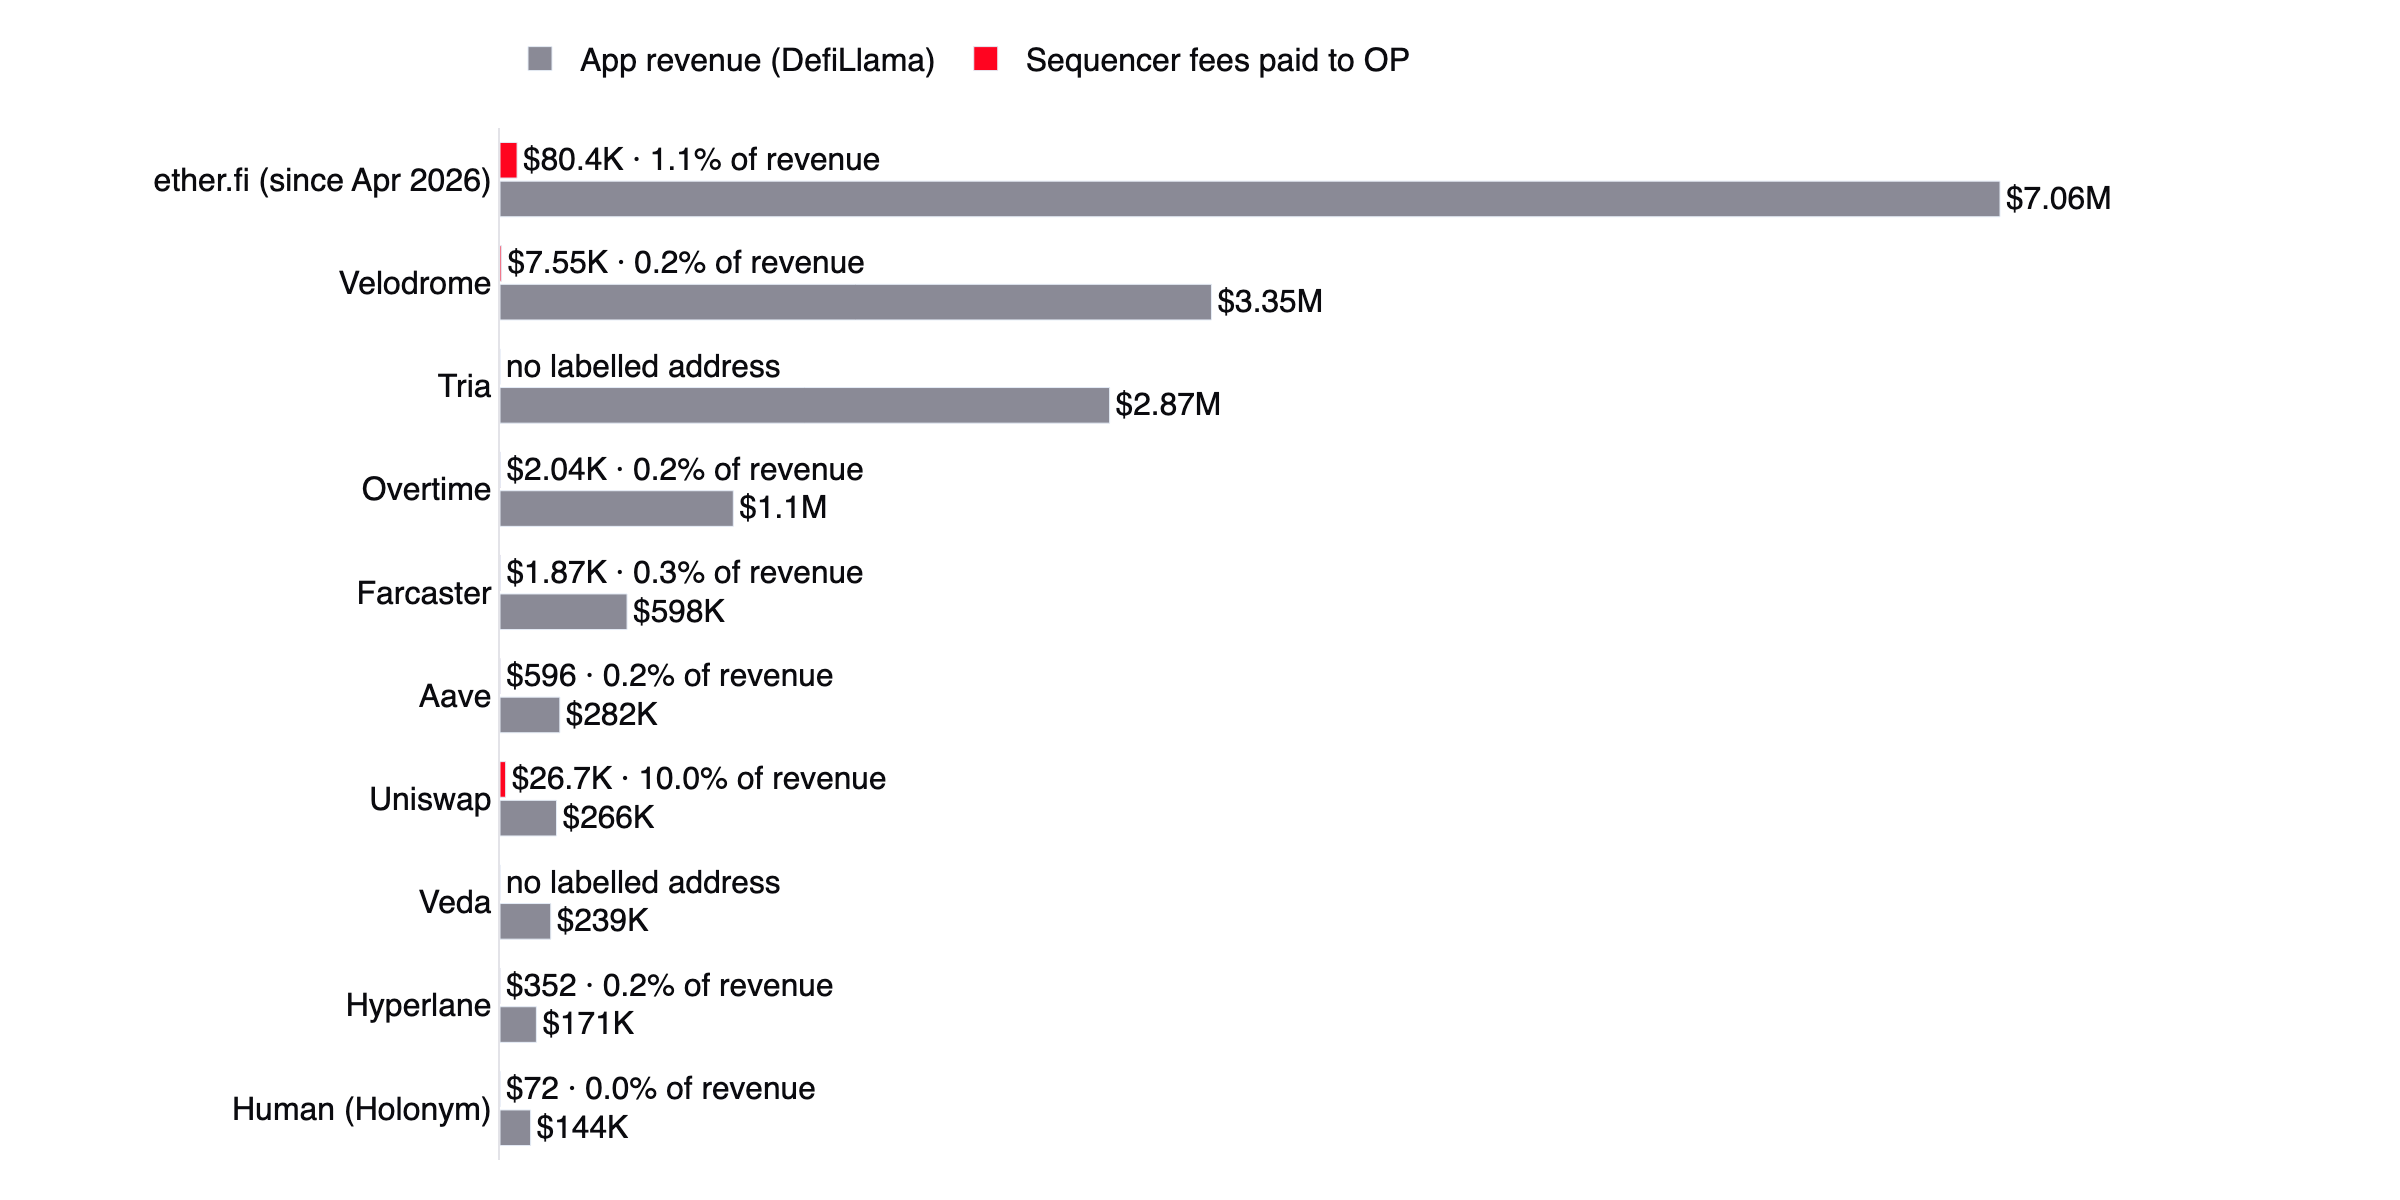

In [16]:
top10 = app_pnl.iloc[::-1]  # largest at the top


def cust_app_pnl(theme: dict) -> go.Figure:
    fig = figure(theme)
    names = [pretty(a) + (" (since Apr 2026)" if a == "etherfi" else "") for a in top10["app"]]  # DefiLlama coverage start
    fig.add_bar(y=names, x=top10["app_revenue_usd"].tolist(), name="App revenue (DefiLlama)", orientation="h", marker_color=theme["series"][2],
                text=[usd(v) for v in top10["app_revenue_usd"]], textposition="outside", textfont=dict(size=16, color=theme["ink"]),
                cliponaxis=False)
    fig.add_bar(y=names, x=top10["fees_paid_to_op_usd"].fillna(0).tolist(), name="Sequencer fees paid to OP", orientation="h",
                marker_color=theme["op"], cliponaxis=False, textposition="outside", textfont=dict(size=16, color=theme["ink"]),
                text=["no labelled address" if pd.isna(p) else f"{usd(p)} · {t:.1%} of revenue"
                      for p, t in zip(top10["fees_paid_to_op_usd"], top10["op_take_of_revenue"])])
    fig.update_layout(barmode="group", bargap=0.25, bargroupgap=0.08, margin=dict(l=250, r=110, t=60, b=20),
                      legend=dict(y=1.1, font_size=16, traceorder="normal"),
                      xaxis=dict(visible=False, range=[0, top10["app_revenue_usd"].max() * 1.12]),
                      yaxis=dict(showgrid=False, tickfont=dict(size=16, color=theme["ink"])))
    return fig


show(cust_app_pnl)